# Tabula-guided Prediction of Fibroblast Rejuvenation Trajectories

In this tutorial, we demonstrate how to use a frozen post-trained Tabula reconstruction model and a frozen lineage-specific discriminator MLP to predict an identity-preserving rejuvenation trajectory for aged human fibroblasts.

The representative example uses **Group A**, with `d2EGFP_A1` as the young sample and `d2EGFP_A2` as the aged sample. The discriminator input is restricted to the **Patient union HVGs** recorded in the accompanying metadata file.

During optimization, the aged-cell expression matrix in **input space** is updated, while Tabula and the discriminator remain frozen. The optimization objective is evaluated from the Tabula-reconstructed expression matrix in **output space**.

## Scope of this tutorial

This notebook demonstrates one representative configuration:

- Biological group: **Group A**
- Young and aged samples: **A1 → A2**
- Input-gene setting: **Patient union HVGs**
- Candidate ranking: **input-space trajectory statistics**

The conclusions reported in the manuscript were not derived from this single configuration alone. The full analysis evaluated three biological groups (A, B, and H), two input-gene settings (Patient specific HVGs and Patient union HVGs), and gene trajectories in both input space and output space. Cross-group overlap, consensus ranking, and independent enrichment analyses were then used to evaluate the robustness and biological relevance of the nominated rejuvenation factors.

Therefore, this notebook illustrates the core Tabula-guided rejuvenation workflow rather than reproducing the complete manuscript analysis.

In [1]:
import sys
sys.path.append("..")

import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import torch
from IPython.display import display
from pytorch_lightning import seed_everything
from scipy.sparse import issparse

from tabula import logger
from tabula.finetune.model.aging import (
    DiscriminatorMLP,
    predict_rejuvenation_trajectory,
)
from tabula.finetune.preprocessor import (
    check_vocab,
    get_pretrained_model,
)
from tabula.finetune.tokenizer import GeneVocab
from tabula.finetune.utils import FinetuneConfig

# Pre-define parameters

- The fibroblast aging dataset, post-trained Tabula checkpoint, discriminator checkpoints, and accompanying metadata can be downloaded from:

  https://drive.google.com/drive/folders/1mdyRqqdN5BzdbH3sWHHkrckkUqKPiNeB?usp=drive_link

- After downloading, place the `aging data` folder under `../data/`, or modify `params["aging_data_root"]` below.
- This tutorial uses the Group A Patient union HVG discriminator.
- `trajectory_params["n_steps"]` is initially set to 50 for a quick local validation. Change it to 3000 for the full trajectory.

In [2]:
params = {
    "seed": 42,
    "aging_data_root": "../data/aging data",
    "config_path": "../data/aging data/post-training/finetune_framework_aging.yaml",
    "model_path": (
        "../data/aging data/post-training/"
        "tabula_fibroblast_posttrained_iter5.pth"
    ),
    
    "discriminator_path": (
        "../data/aging data/optimization/"
        "discriminator_training_patient_union_hvg/"
        "discriminator_group_A.pt"
    ),
    "discriminator_meta_path": (
        "../data/aging data/optimization/"
        "discriminator_training_patient_union_hvg/"
        "discriminator_group_A.meta.json"
    ),
    "save_folder": "aging_out/group_A_patient_union_hvg",
    
    # in case of patient specific
    # "discriminator_path": (
    # "../data/aging data/optimization/"
    # "discriminator_training_patient_specific_hvg/"
    # "discriminator_group_A.pt"
    # ),
    # "discriminator_meta_path": (
    #     "../data/aging data/optimization/"
    #     "discriminator_training_patient_specific_hvg/"
    #     "discriminator_group_A.meta.json"
    # ),
    # "save_folder": "aging_out/group_A_patient_specific_hvg",

    "device": "cuda:1",  # "cuda:0" or "cpu"
}

data_params = {
    "data_path": (
        "../data/aging data/optimization/"
        "fibroblast_aging_method_c.h5ad"
    ),
    "vocab_path": "../resource/vocab.json",
    "young_guide": "d2EGFP_A1",
    "aged_guide": "d2EGFP_A2",
    "young_age": 29.0,
    "aged_age": 46.0,
}

trajectory_params = {
    "lower_bound_age": 17.0,
    "identity_preservation_weight": 1.0,
    "learning_rate": 1e-4,
    "n_steps": 3000, 
    "population_center": "median",
    "target_calibration_space": "output",
    "discriminator_input_transform": "none",
    "fold_change_epsilon": 1e-8,
    "reconstruction_batch_size": 64,
}

In [3]:
seed_everything(params["seed"])
os.makedirs(params["save_folder"], exist_ok=True)

if params["device"] != "cpu" and not torch.cuda.is_available():
    logger.warning("CUDA is not available. Falling back to CPU.")
    params["device"] = "cpu"

device = torch.device(params["device"])

# finetune_config = FinetuneConfig(
#     seed=params["seed"],
#     config_path=params["config_path"],
# )

# # The aging reconstruction model was used without batch embeddings.
# finetune_config.set_finetune_param("enable_batch", False)
finetune_config = FinetuneConfig(
    seed=params["seed"],
    config_path=params["config_path"],
)

# Compatibility with the historical aging YAML.
# Only supply optional values that are missing from the original config.
legacy_optional_defaults = {
    "explicit_zero_prob": False,
    "do_mgm": False,
    "do_cmgm": False,
    "cmgm_decoder_style": "inner product",
    "do_dab": False,
    "embed_style": "cls",
}

for key, default_value in legacy_optional_defaults.items():
    try:
        finetune_config.get_finetune_param(key)
    except Exception:
        finetune_config.set_finetune_param(
            key,
            default_value,
        )

# The aging reconstruction model was used without batch embeddings.
finetune_config.set_finetune_param(
    "enable_batch",
    False,
)

logger.info(
    f"Configuration loaded from {params['config_path']}; "
    f"results will be saved to {params['save_folder']}."
)
print("Device:", device)

Global seed set to 42


Tabula - INFO - Configuration loaded from ../data/aging data/post-training/finetune_framework_aging.yaml; results will be saved to aging_out/group_A_patient_union_hvg.
Device: cuda:1


# Check the required files

The notebook uses one post-trained Tabula checkpoint, one Group A discriminator checkpoint, its metadata file, the fibroblast AnnData object, the aging configuration YAML, and the Tabula vocabulary.

In [4]:
required_paths = [
    params["config_path"],
    params["model_path"],
    params["discriminator_path"],
    params["discriminator_meta_path"],
    data_params["data_path"],
    data_params["vocab_path"],
]

missing_paths = [path for path in required_paths if not os.path.exists(path)]
if missing_paths:
    raise FileNotFoundError(
        "The following required files were not found:\n"
        + "\n".join(missing_paths)
    )

logger.info("All required files were found.")

Tabula - INFO - All required files were found.


# Load the discriminator metadata

The metadata file stores the exact Patient union HVG list and its column order. The expression matrix must be sliced in this order before it is passed to the discriminator or Tabula.

In [5]:
with open(
    params["discriminator_meta_path"],
    "r",
    encoding="utf-8",
) as file:
    discriminator_meta = json.load(file)

genes_hvg = (
    discriminator_meta.get("genes_hvg")
    or discriminator_meta.get("genes")
)
if genes_hvg is None:
    raise KeyError(
        "The discriminator metadata does not contain "
        "'genes_hvg' or 'genes'."
    )

genes_hvg = [str(gene) for gene in genes_hvg]
hidden_features = int(
    discriminator_meta.get(
        "hidden",
        discriminator_meta.get("train", {}).get("hidden", 64),
    )
)

metadata_lineage = discriminator_meta.get("lineage")
if metadata_lineage is not None and str(metadata_lineage) != "A":
    raise ValueError(
        f"Expected Group A metadata, but found lineage={metadata_lineage!r}."
    )

if len(genes_hvg) != len(set(genes_hvg)):
    raise ValueError("The metadata contains duplicated input genes.")

print("Lineage:", metadata_lineage)
print("Number of discriminator input genes:", len(genes_hvg))
print("Hidden features:", hidden_features)
print("First five input genes:", genes_hvg[:5])

Lineage: A
Number of discriminator input genes: 1200
Hidden features: 64
First five input genes: ['LINC01409', 'LINC00115', 'PERM1', 'ISG15', 'AGRN']


# Load and align the fibroblast expression data

The AnnData object is first restricted to genes represented in the Tabula vocabulary. It is then sliced to the exact ordered HVG list recorded in the Group A discriminator metadata.

In [6]:
adata_full = sc.read_h5ad(data_params["data_path"])

if "guide" not in adata_full.obs.columns:
    raise KeyError("The AnnData object does not contain adata.obs['guide'].")

adata_full.var["gene_name"] = adata_full.var_names.astype(str)
adata_full, removed_genes = check_vocab(
    adata_full,
    data_params["vocab_path"],
)

missing_hvg = [
    gene for gene in genes_hvg
    if gene not in adata_full.var_names
]
if missing_hvg:
    raise ValueError(
        f"{len(missing_hvg)} discriminator input genes are missing "
        f"from the AnnData object after vocabulary filtering. "
        f"Examples: {missing_hvg[:10]}"
    )

adata_hvg = adata_full[:, genes_hvg].copy()

print("Full data shape after vocabulary filtering:", adata_full.shape)
print("Group A discriminator input shape:", adata_hvg.shape)
print("Genes removed because they were absent from the vocabulary:", len(removed_genes))

Full data shape after vocabulary filtering: (1498, 24285)
Group A discriminator input shape: (1498, 1200)
Genes removed because they were absent from the vocabulary: 0


# Prepare the matched young and aged fibroblast groups

For this representative setting, `d2EGFP_A1` is the young group and `d2EGFP_A2` is the aged group.

In [7]:
young_mask = (
    adata_hvg.obs["guide"].astype(str)
    == data_params["young_guide"]
)
aged_mask = (
    adata_hvg.obs["guide"].astype(str)
    == data_params["aged_guide"]
)

young_adata = adata_hvg[young_mask].copy()
aged_adata = adata_hvg[aged_mask].copy()

if young_adata.n_obs == 0 or aged_adata.n_obs == 0:
    raise ValueError(
        "No cells were found for one or both requested guides: "
        f"{data_params['young_guide']} and {data_params['aged_guide']}."
    )

def to_dense_float32(matrix):
    if issparse(matrix):
        matrix = matrix.toarray()
    return np.asarray(matrix, dtype=np.float32)

young_expression_np = to_dense_float32(young_adata.X)
aged_expression_np = to_dense_float32(aged_adata.X)

young_expression = torch.tensor(
    young_expression_np,
    dtype=torch.float32,
    device=device,
)
aged_expression = torch.tensor(
    aged_expression_np,
    dtype=torch.float32,
    device=device,
)

group_summary = pd.DataFrame(
    {
        "Group": ["Young", "Aged"],
        "Guide": [
            data_params["young_guide"],
            data_params["aged_guide"],
        ],
        "Chronological age": [
            data_params["young_age"],
            data_params["aged_age"],
        ],
        "Cells": [
            young_adata.n_obs,
            aged_adata.n_obs,
        ],
        "Input genes": [
            young_adata.n_vars,
            aged_adata.n_vars,
        ],
    }
)
display(group_summary)

,Group,Guide,Chronological age,Cells,Input genes
0,Young,d2EGFP_A1,29.0,145,1200
1,Aged,d2EGFP_A2,46.0,67,1200


# Load the frozen discriminator MLP

The lineage-specific discriminator predicts two normalized scores from the selected expression profile:

1. normalized age score;
2. normalized fibroblast identity score.

Its parameters remain frozen throughout rejuvenation trajectory prediction.

In [8]:
discriminator = DiscriminatorMLP(
    in_features=len(genes_hvg),
    hidden_features=hidden_features,
).to(device)

discriminator_state_dict = torch.load(
    params["discriminator_path"],
    map_location=device,
)
discriminator.load_state_dict(
    discriminator_state_dict,
    strict=True,
)
discriminator.eval()
discriminator.requires_grad_(False)

with torch.no_grad():
    test_prediction = discriminator(aged_expression[:2])

if test_prediction.shape != (min(2, aged_expression.shape[0]), 2):
    raise RuntimeError(
        "Unexpected discriminator output shape: "
        f"{tuple(test_prediction.shape)}"
    )

logger.info("The Group A discriminator was loaded successfully.")

Tabula - INFO - The Group A discriminator was loaded successfully.


# Load the frozen post-trained Tabula model

The reconstruction model is initialized from `finetune_framework_aging.yaml` and loaded from the post-training checkpoint. Its parameters remain frozen; only the aged-cell input expression matrix is optimized.

In [9]:
reconstruction_model = get_pretrained_model(
    finetune_config=finetune_config,
    model_path=params["model_path"],
    device=params["device"],
)
reconstruction_model.eval()
reconstruction_model.requires_grad_(False)

logger.info("The post-trained Tabula reconstruction model was loaded successfully.")

Tabula - INFO - Loading FlashAttention Tabula from path: ../data/aging data/post-training/tabula_fibroblast_posttrained_iter5.pth


/mnt/first19T/linjh/anaconda3/envs/sctabular/lib/python3.10/site-packages/torch/nn/init.py:405: UserWarning: Initializing zero-element tensors is a no-op
  warnings.warn("Initializing zero-element tensors is a no-op")


Tabula - ERROR - Error loading model from path: ../data/aging data/post-training/tabula_fibroblast_posttrained_iter5.pth, switch to load specific weights.
Tabula - INFO - Loading params feature_tokenizer.gene_encoder.embedding.weight with shape torch.Size([60697, 192])
Tabula - INFO - Loading params feature_tokenizer.gene_encoder.enc_norm.weight with shape torch.Size([192])
Tabula - INFO - Loading params feature_tokenizer.gene_encoder.enc_norm.bias with shape torch.Size([192])
Tabula - INFO - Loading params feature_tokenizer.value_encoder.weight with shape torch.Size([1200, 192])
Tabula - INFO - Loading params feature_tokenizer.value_encoder.bias with shape torch.Size([1200, 192])
Tabula - INFO - Loading params feature_tokenizer.value_encoder.enc_norm.weight with shape torch.Size([192])
Tabula - INFO - Loading params feature_tokenizer.value_encoder.enc_norm.bias with shape torch.Size([192])
Tabula - INFO - Loading params bn.weight with shape torch.Size([192])
Tabula - INFO - Loading pa

# Convert the ordered input genes to Tabula vocabulary IDs

In [10]:
vocab = GeneVocab.from_file(data_params["vocab_path"])

genes_missing_from_vocab = [
    gene for gene in genes_hvg
    if gene not in vocab
]
if genes_missing_from_vocab:
    raise KeyError(
        f"{len(genes_missing_from_vocab)} discriminator genes are "
        f"missing from the Tabula vocabulary. "
        f"Examples: {genes_missing_from_vocab[:10]}"
    )

gene_ids = torch.tensor(
    [vocab[gene] for gene in genes_hvg],
    dtype=torch.int64,
    device=device,
)

print("Gene ID tensor shape:", tuple(gene_ids.shape))

Gene ID tensor shape: (1200,)


# Predict the rejuvenation trajectory

At every step, the current input-space matrix is reconstructed by the frozen Tabula model. The reconstructed output-space matrix is evaluated by the frozen discriminator. The objective moves the normalized age score toward the lower-bound age target while moving the normalized identity score toward the young-group identity target.

The manuscript setting uses an identity-preservation weight of `5.0`. The first local run uses 50 steps for rapid validation. Set `trajectory_params["n_steps"] = 3000` for the full trajectory.

In [14]:
print("Discriminator checkpoint:")
print(params["discriminator_path"])

print("\nDiscriminator metadata:")
print(params["discriminator_meta_path"])

print("\nMetadata summary:")
print({
    "lineage": discriminator_meta.get("lineage"),
    "guides": discriminator_meta.get("guides"),
    "hvg": discriminator_meta.get("hvg"),
    "source": discriminator_meta.get("source"),
})

print("\nLoaded expression:")
print("young guide:", data_params["young_guide"])
print("aged guide:", data_params["aged_guide"])
print("young shape:", tuple(young_expression.shape))
print("aged shape:", tuple(aged_expression.shape))
print("number of HVGs:", len(genes_hvg))
print("first five HVGs:", genes_hvg[:5])

Discriminator checkpoint:
../data/aging data/optimization/discriminator_training_patient_union_hvg/discriminator_group_A.pt

Discriminator metadata:
../data/aging data/optimization/discriminator_training_patient_union_hvg/discriminator_group_A.meta.json

Metadata summary:
{'lineage': 'A', 'guides': ['d2EGFP_A1', 'd2EGFP_A2'], 'hvg': 1200, 'source': None}

Loaded expression:
young guide: d2EGFP_A1
aged guide: d2EGFP_A2
young shape: (145, 1200)
aged shape: (67, 1200)
number of HVGs: 1200
first five HVGs: ['LINC01409', 'LINC00115', 'PERM1', 'ISG15', 'AGRN']


In [15]:
result = predict_rejuvenation_trajectory(
    aged_expression=aged_expression,
    young_expression=young_expression,
    gene_ids=gene_ids,
    reconstruction_model=reconstruction_model,
    discriminator=discriminator,
    young_age=data_params["young_age"],
    aged_age=data_params["aged_age"],
    lower_bound_age=trajectory_params["lower_bound_age"],
    identity_preservation_weight=(
        trajectory_params["identity_preservation_weight"]
    ),
    learning_rate=trajectory_params["learning_rate"],
    n_steps=trajectory_params["n_steps"],
    population_center=trajectory_params["population_center"],
    target_calibration_space=(
        trajectory_params["target_calibration_space"]
    ),
    discriminator_input_transform=(
        trajectory_params["discriminator_input_transform"]
    ),
    fold_change_epsilon=(
        trajectory_params["fold_change_epsilon"]
    ),
    reconstruction_batch_size=(
        trajectory_params["reconstruction_batch_size"]
    ),
    log_every=max(trajectory_params["n_steps"] // 10, 1),
)

Tabula - INFO - Starting Tabula-guided rejuvenation trajectory prediction for 3000 steps.
Tabula - INFO - Rejuvenation trajectory step 300: loss=0.736291.
Tabula - INFO - Rejuvenation trajectory step 600: loss=0.446758.
Tabula - INFO - Rejuvenation trajectory step 900: loss=0.282625.
Tabula - INFO - Rejuvenation trajectory step 1200: loss=0.177519.
Tabula - INFO - Rejuvenation trajectory step 1500: loss=0.104535.
Tabula - INFO - Rejuvenation trajectory step 1800: loss=0.054745.
Tabula - INFO - Rejuvenation trajectory step 2100: loss=0.023387.
Tabula - INFO - Rejuvenation trajectory step 2400: loss=0.007651.
Tabula - INFO - Rejuvenation trajectory step 2700: loss=0.001987.
Tabula - INFO - Rejuvenation trajectory step 3000: loss=0.000517.
Tabula - INFO - Tabula-guided rejuvenation trajectory prediction finished.


# Summarize the score targets and trajectory endpoints

The optimization objective is evaluated in output space. The table below compares the initial aged-cell score center, the optimization target, and the final predicted score center.

In [16]:
score_summary = pd.DataFrame(
    {
        "Score": [
            "Normalized age score",
            "Normalized identity score",
        ],
        "Initial aged center": [
            result["center_age_score_output"][0].item(),
            result["center_identity_score_output"][0].item(),
        ],
        "Target": [
            result["lower_bound_age_score"].item(),
            result["young_identity_score"].item(),
        ],
        "Final predicted center": [
            result["center_age_score_output"][-1].item(),
            result["center_identity_score_output"][-1].item(),
        ],
    }
)

display(score_summary)

,Score,Initial aged center,Target,Final predicted center
0,Normalized age score,1.519945,0.875298,0.875401
1,Normalized identity score,1.328815,1.476758,1.476773


# Visualize the predicted rejuvenation trajectory

The two panels follow the central visualization used in the manuscript: the normalized age score is driven toward the lower-bound age target, while the normalized identity score is driven toward the young-group identity target. Both trajectories shown here are evaluated in Tabula output space.

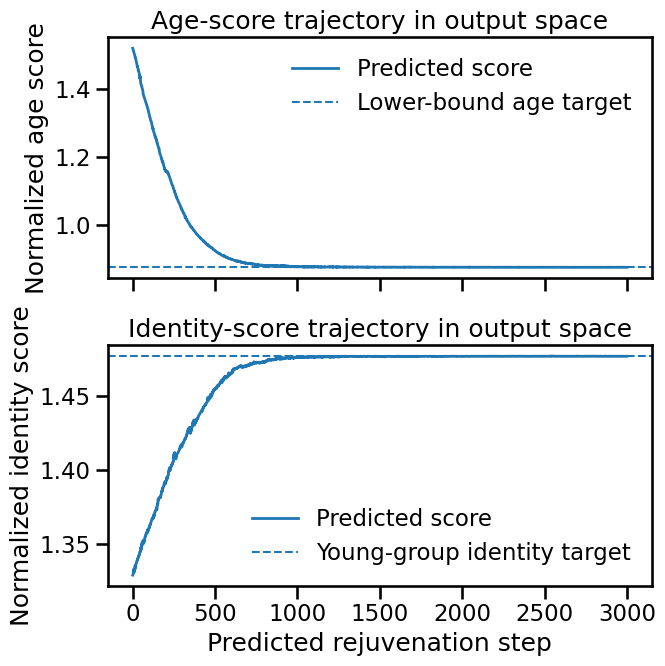

Saved: aging_out/group_A_patient_union_hvg/group_A_score_trajectories.png


In [17]:
steps = result["steps"].detach().cpu().numpy()
age_trajectory = (
    result["center_age_score_output"]
    .detach()
    .cpu()
    .numpy()
)
identity_trajectory = (
    result["center_identity_score_output"]
    .detach()
    .cpu()
    .numpy()
)

lower_bound_age_score = (
    result["lower_bound_age_score"]
    .detach()
    .cpu()
    .item()
)
young_identity_score = (
    result["young_identity_score"]
    .detach()
    .cpu()
    .item()
)

fig, axes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(7, 7),
    sharex=True,
)

axes[0].plot(
    steps,
    age_trajectory,
    linewidth=2,
    label="Predicted score",
)
axes[0].axhline(
    lower_bound_age_score,
    linestyle="--",
    linewidth=1.5,
    label="Lower-bound age target",
)
axes[0].set_ylabel("Normalized age score")
axes[0].set_title("Age-score trajectory in output space")
axes[0].legend(frameon=False)

axes[1].plot(
    steps,
    identity_trajectory,
    linewidth=2,
    label="Predicted score",
)
axes[1].axhline(
    young_identity_score,
    linestyle="--",
    linewidth=1.5,
    label="Young-group identity target",
)
axes[1].set_xlabel("Predicted rejuvenation step")
axes[1].set_ylabel("Normalized identity score")
axes[1].set_title("Identity-score trajectory in output space")
axes[1].legend(frameon=False)

plt.tight_layout()

trajectory_figure_path = os.path.join(
    params["save_folder"],
    "group_A_score_trajectories.png",
)
fig.savefig(
    trajectory_figure_path,
    dpi=300,
    bbox_inches="tight",
)
plt.show()

print("Saved:", trajectory_figure_path)

# Rank candidate rejuvenation factors

For the representative input-space analysis, each gene is ranked using the manuscript rule:

1. number of optimization steps with a positive mean expression change (`n_up`), in descending order;
2. accumulated positive trajectory path (`pos_path`), in descending order to break ties.

`net_change` reports the final mean expression change relative to the initial aged-cell matrix. The table below corresponds only to Group A with Patient union HVGs; the manuscript conclusions were derived from multiple settings.

In [18]:
ranking = pd.DataFrame(
    {
        "gene": genes_hvg,
        "n_up": (
            result["n_up_input"]
            .detach()
            .cpu()
            .numpy()
        ),
        "n_down": (
            result["n_down_input"]
            .detach()
            .cpu()
            .numpy()
        ),
        "pos_path": (
            result["pos_path_input"]
            .detach()
            .cpu()
            .numpy()
        ),
        "neg_path": (
            result["neg_path_input"]
            .detach()
            .cpu()
            .numpy()
        ),
        "net_change": (
            result["net_change_input"]
            .detach()
            .cpu()
            .numpy()
        ),
    }
)

ranking = ranking.sort_values(
    by=["n_up", "pos_path"],
    ascending=[False, False],
).reset_index(drop=True)

ranking.insert(
    0,
    "rank",
    np.arange(1, len(ranking) + 1),
)

ranking_display = ranking[
    [
        "rank",
        "gene",
        "n_up",
        "pos_path",
        "net_change",
    ]
].rename(
    columns={
        "rank": "Rank",
        "gene": "Gene",
        "n_up": "Upregulated steps",
        "pos_path": "Accumulated positive path",
        "net_change": "Final net change",
    }
)

display(ranking_display.head(20))

,Rank,Gene,Upregulated steps,Accumulated positive path,Final net change
0,1,POSTN,3000,0.064124,0.064124
1,2,CDCA2,3000,0.063579,0.063579
2,3,MT1H,3000,0.062545,0.062545
3,4,KIF4A,3000,0.062063,0.062063
4,5,CEP126,3000,0.061216,0.061216
5,6,ITGA5,3000,0.060555,0.060555
6,7,ANLN,3000,0.060347,0.060347
7,8,MCTP2,3000,0.059264,0.059264
8,9,PSG1,3000,0.059048,0.059048
9,10,LINC02604,3000,0.059005,0.059005


# Export the trajectory and ranking results

In [19]:
ranking_path = os.path.join(
    params["save_folder"],
    "group_A_patient_specific_hvg_input_space_ranking.csv",
)
ranking.to_csv(ranking_path, index=False)

trajectory_path = os.path.join(
    params["save_folder"],
    "group_A_patient_specific_hvg_trajectory.pt",
)
torch.save(
    {
        key: value.detach().cpu()
        if torch.is_tensor(value)
        else value
        for key, value in result.items()
    },
    trajectory_path,
)

print("Saved ranking:", ranking_path)
print("Saved trajectory:", trajectory_path)

Saved ranking: aging_out/group_A_patient_union_hvg/group_A_patient_specific_hvg_input_space_ranking.csv
Saved trajectory: aging_out/group_A_patient_union_hvg/group_A_patient_specific_hvg_trajectory.pt


# Relationship to the full manuscript analysis

The ranked genes shown above correspond only to **Group A**, **Patient specific HVGs**, and **input-space trajectory statistics**.

In the manuscript, the same framework was extended to Groups A, B, and H, to both Patient specific and Patient union HVGs, and to both input-space and output-space rankings. Cross-group overlaps, consensus rankings, and independent enrichment analyses were then used to evaluate the robustness and biological relevance of the nominated rejuvenation factors.